# Machine Learning — Renewable Electricity Production

This notebook applies a machine learning method to analyze the temporal trend of renewable electricity production in Italy from 2000 to 2024.

The analysis uses a linear regression model to examine the relationship between time and total annual renewable electricity production.

The objective is to:

- build a simple regression model;
- evaluate its performance;
- interpret the model coefficients;
- analyze the residuals;
- discuss the limitations of using a linear model for this time series.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the cleaned gross renewable electricity production dataset.
df = pd.read_csv("../data/processed/terna_renewable_production_2000_2024.csv")

df.head()

,year,region,province,renewable_source,production_GWh
0,2000,Abruzzo,Chieti,Bioenergie,0.000000
1,2000,Abruzzo,Chieti,Idrico,452.350340
2,2000,Abruzzo,Chieti,Geotermoelettrico,0.000000
3,2000,Abruzzo,Chieti,Fotovoltaico,1.182084
4,2000,Abruzzo,Chieti,Eolico,0.186600


In [3]:
# Aggregate gross renewable electricity production by year for the regression analysis.
annual_production = (
    df.groupby("year")["production_GWh"]
    .sum()
    .reset_index()
)

annual_production.head()

,year,production_GWh
0,2000,50978.473439
1,2001,54458.374458
2,2002,48298.552613
3,2003,47060.825353
4,2004,54124.627682


In [4]:
# Use year as the predictor variable.
X = annual_production[["year"]]

# Use annual renewable electricity production as the target variable.
y = annual_production["production_GWh"]

X.shape, y.shape

((25, 1), (25,))

In [5]:
# Create and fit a linear regression model using year as the predictor.
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3768.36]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.496e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [6]:
model.coef_, model.intercept_

(array([3768.36136468]), np.float64(-7495935.847689232))

In [7]:
# Generate predicted annual production values using the fitted regression model.
y_pred = model.predict(X)

y_pred[:5]

array([40786.8816774 , 44555.24304208, 48323.60440677, 52091.96577145,
       55860.32713613])

In [8]:
# Calculate the coefficient of determination (R²) for the fitted model.
r2 = r2_score(y, y_pred)

r2

0.8500147121468027

In [9]:
# Calculate the root mean squared error (RMSE) in GWh.
rmse = mean_squared_error(y, y_pred) ** 0.5

rmse

11414.72159480253

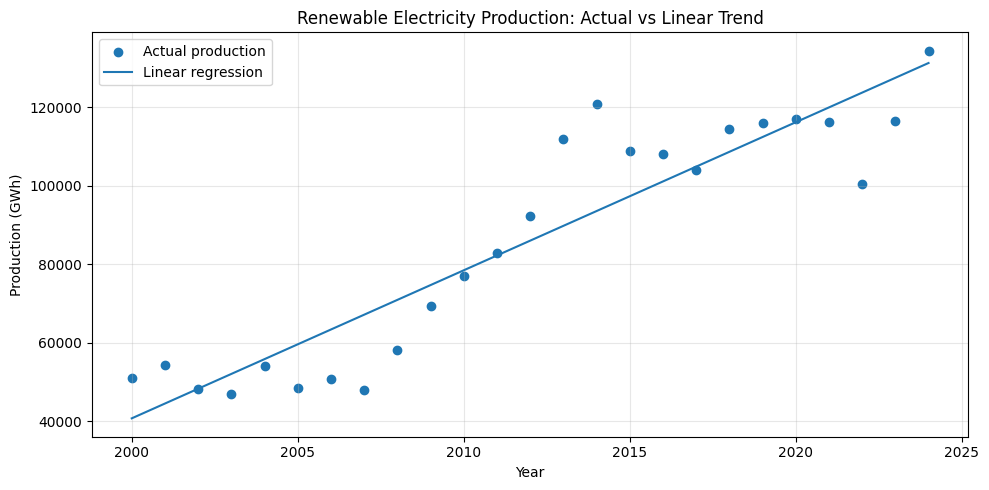

In [10]:
# Plot observed annual production and the fitted linear regression trend.
plt.figure(figsize=(10, 5))

plt.scatter(X["year"], y, label="Actual production")
plt.plot(X["year"], y_pred, label="Linear regression")

plt.title("Renewable Electricity Production: Actual vs Linear Trend")
plt.xlabel("Year")
plt.ylabel("Production (GWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Calculate residuals as the difference between observed and predicted production.
residuals = y - y_pred

residuals.describe()

count    2.500000e+01
mean    -2.569868e-10
std      1.165010e+04
min     -2.322429e+04
25%     -5.446770e+03
50%     -2.505179e+01
75%      6.215156e+03
max      2.713493e+04
Name: production_GWh, dtype: float64

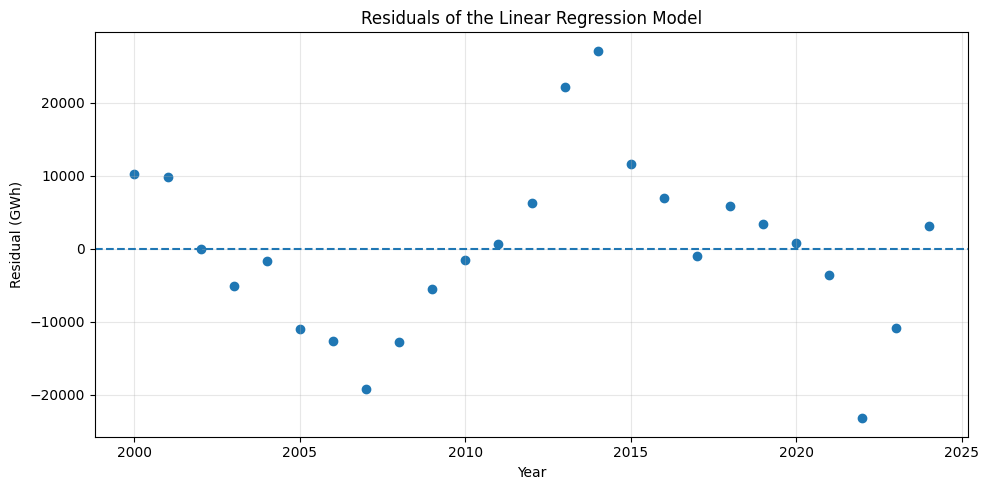

In [12]:
# Plot residuals over time to assess systematic patterns in the model errors.
plt.figure(figsize=(10, 5))

plt.scatter(X["year"], residuals)
plt.axhline(y=0, linestyle="--")

plt.title("Residuals of the Linear Regression Model")
plt.xlabel("Year")
plt.ylabel("Residual (GWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Model Evaluation

The linear regression model identifies a clear positive long-term trend in Italian renewable electricity production.

The estimated coefficient indicates an average increase of approximately **3,768 GWh per year** over the 2000–2024 period.

The model achieved:

- **R² = 0.85**
- **RMSE ≈ 11,415 GWh**

The R² indicates that the linear time trend accounts for approximately 85% of the observed variation in annual renewable electricity production within the analyzed sample.

However, the residuals show temporal patterns rather than completely random dispersion around zero. This indicates that a simple linear model does not capture all the dynamics of renewable electricity production.

The model should therefore be interpreted primarily as a description of the long-term trend rather than as a forecasting model.

## Methodological Limitations

This analysis uses only 25 annual observations, covering the period from 2000 to 2024.

The regression model was fitted and evaluated on the same historical observations. Therefore, the reported R² and RMSE measure in-sample fit and should not be interpreted as estimates of out-of-sample forecasting performance.

A random train-test split was not used because the observations form a time series and their temporal order should be preserved.

A more advanced forecasting analysis would require time-series validation techniques and potentially additional explanatory variables.